In [1]:
# Import Modules
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

# Constants
batch_size = 32
IMG_WIDTH = 224
IMG_HEIGHT = 224
CHANNELS = 3
CLASSES = 9
train_dir = 'Date_Fruit/train'
validation_dir = 'Date_Fruit/test'



print(tf.keras.__version__)


train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
validation_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Load Training Data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

# Load Validation Data
validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(IMG_WIDTH, IMG_HEIGHT),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Create Model
model_ENB0 = EfficientNetB0(include_top=False, weights='imagenet', input_shape=(IMG_WIDTH, IMG_HEIGHT, CHANNELS))
model_ENB0.trainable = False  # Freeze the pre-trained base model

model = Sequential([
    model_ENB0,
    GlobalAveragePooling2D(),
    Dropout(0.2),
    Dense(CLASSES, activation="softmax")
])

model.summary()

# Compile Model
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-2),
    metrics=['accuracy']
)

# Training Parameters
STEP_SIZE_TRAIN = train_generator.n // train_generator.batch_size
STEP_SIZE_VALID = validation_generator.n // validation_generator.batch_size
epochs = 20

# Train the Model
history = model.fit(
    train_generator,
   # steps_per_epoch=STEP_SIZE_TRAIN,
    epochs=epochs,
    validation_data=validation_generator,
   # validation_steps=STEP_SIZE_VALID
)

# Plot Training History 
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(acc, label='Training Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.legend()
    plt.title('Accuracy')

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(loss, label='Training Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.legend()
    plt.title('Loss')

    plt.show()

plot_training_history(history)


3.5.0
Found 4624 images belonging to 9 classes.
Found 502 images belonging to 9 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,061,100 (15.49 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/50


D:\anaconda3\envs\CS462\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


145/145 ━━━━━━━━━━━━━━━━━━━━ 112s 708ms/step - accuracy: 0.7234 - loss: 0.8375 - val_accuracy: 0.9243 - val_loss: 0.2350
Epoch 2/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 100s 686ms/step - accuracy: 0.9258 - loss: 0.2300 - val_accuracy: 0.9482 - val_loss: 0.1743
Epoch 3/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 107s 735ms/step - accuracy: 0.9429 - loss: 0.1557 - val_accuracy: 0.9442 - val_loss: 0.1457
Epoch 4/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 105s 717ms/step - accuracy: 0.9494 - loss: 0.1440 - val_accuracy: 0.9343 - val_loss: 0.1895
Epoch 5/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 105s 722ms/step - accuracy: 0.9563 - loss: 0.1253 - val_accuracy: 0.9522 - val_loss: 0.1624
Epoch 6/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 105s 724ms/step - accuracy: 0.9535 - loss: 0.1252 - val_accuracy: 0.9562 - val_loss: 0.1269
Epoch 7/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 103s 709ms/step - accuracy: 0.9629 - loss: 0.1112 - val_accuracy: 0.9363 - val_loss: 0.2122
Epoch 8/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 104s 714ms/step - accuracy: 0.9564 - loss: 0.12

KeyboardInterrupt: 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,084,160 (15.58 MB)

 Trainable params: 1,354,297 (5.17 MB)

 Non-trainable params: 2,706,803 (10.33 MB)

 Optimizer params: 23,060 (90.08 KB)

Epoch 1/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.9651 - loss: 0.1019 - val_accuracy: 0.9582 - val_loss: 0.1350
Epoch 2/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.9767 - loss: 0.0680 - val_accuracy: 0.9502 - val_loss: 0.1966
Epoch 3/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 154s 1s/step - accuracy: 0.9853 - loss: 0.0361 - val_accuracy: 0.9522 - val_loss: 0.2014
Epoch 4/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - accuracy: 0.9844 - loss: 0.0473 - val_accuracy: 0.9661 - val_loss: 0.1360
Epoch 5/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.9918 - loss: 0.0251 - val_accuracy: 0.9602 - val_loss: 0.1619
Epoch 6/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.9951 - loss: 0.0148 - val_accuracy: 0.9582 - val_loss: 0.1796
Epoch 7/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.9919 - loss: 0.0239 - val_accuracy: 0.9602 - val_loss: 0.1809
Epoch 8/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.9945 - loss: 0.0160 - val_accu

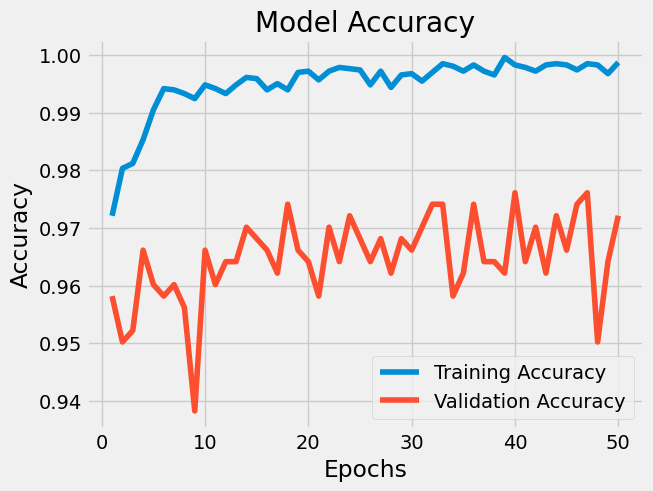

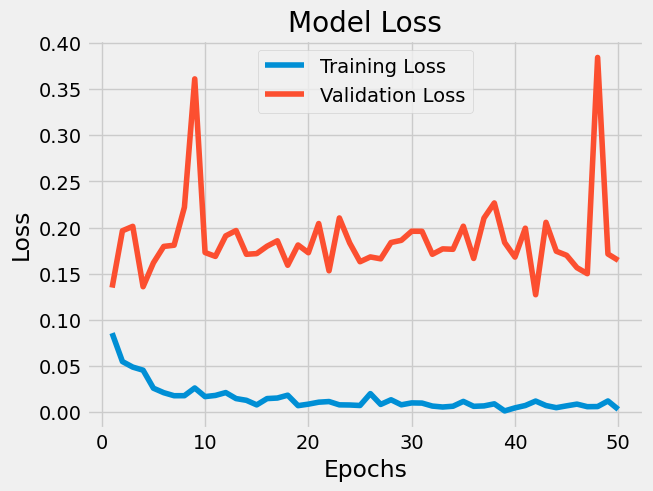

ValueError: The filename must end in `.weights.h5`. Received: filepath=Fruits360_EfficientNetB0_weights.h5

In [2]:
# Unfreezing
model_ENB0.trainable = True
set_trainable = False

for layer in model_ENB0.layers:
    if layer.name == 'block6d_se_excite':
        set_trainable = True
    if set_trainable:
        if not isinstance(layer, tf.keras.layers.BatchNormalization):  # Correct reference
            layer.trainable = True
        else:
            layer.trainable = False
    else:
        layer.trainable = False

# Updated Model Summary
model.summary()

# Fine-Tuning
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # Correct reference
    metrics=['accuracy']
)

# Training Parameters
STEP_SIZE_TRAIN = train_generator.n // train_generator.batch_size
STEP_SIZE_VALID = validation_generator.n // validation_generator.batch_size
epochs = 50

# Train the Model
history = model.fit(
    train_generator,
   # steps_per_epoch=STEP_SIZE_TRAIN,
    epochs=epochs,
    validation_data=validation_generator,
  #  validation_steps=STEP_SIZE_VALID
)

# Plot Accuracy
plt.style.use('fivethirtyeight')
plt.title('Model Accuracy')
plt.plot(range(1, epochs + 1), history.history['accuracy'], label="Training Accuracy")
plt.plot(range(1, epochs + 1), history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot Loss
plt.style.use('fivethirtyeight')
plt.title('Model Loss')
plt.plot(range(1, epochs + 1), history.history['loss'], label="Training Loss")
plt.plot(range(1, epochs + 1), history.history['val_loss'], label="Validation Loss")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Save the Model and Weights
model.save('Fruits360_EfficientNetB0.h5')
model.save_weights('Fruits360_EfficientNetB0_weights.h5')
